# Actividad: Clasificación con Datos Desbalanceados — Oil-Spill

## Maestría en Inteligencia Artificial Aplicada

**Tecnológico de Monterrey**

**Curso:** Inteligencia Artificial y Aprendizaje Automático

**Profesor:** Luis Eduardo Falcón Morales

**Nombre:** Carlos Rodrigo Salguero Alcántara

**Matrícula:** A00833341


## Introducción

Esta actividad aborda un problema de **clasificación binaria con clases desbalanceadas**, usando el conjunto de datos *oil-spill* (derrame de petróleo). El buen desempeño de un modelo de clasificación requiere decidir desde el inicio si las clases de la variable de salida están balanceadas o no. Durante el preprocesamiento encapsulamos las transformaciones en un `Pipeline` para automatizarlas y evitar el filtrado de información (*data leakage*).

Aquí se estudia el impacto de técnicas básicas de balanceo (en particular `class_weight`), el uso de métricas adecuadas bajo desbalanceo ($G\_mean$, reportes de *imbalanced-learn*) y la interpretación de curvas **ROC** y **Precisión–Recall**, además del ajuste del umbral de decisión según costos de negocio.


### Objetivos de aprendizaje

El desarrollo de esta actividad contribuye al cumplimiento de los objetivos:

- **2.1** Identificar problemáticas de clasificación cuando los datos no están balanceados.
- **2.2** Aplicar técnicas de balanceo de clases, uso de métricas adecuadas y gráficos ROC y PR.


### Contexto del problema

- La actividad se basa en los datos conocidos como **"oil-spill"** (derrame de petróleo).
- En la web existen varias referencias a este mismo problema, pero el archivo de datos no siempre es idéntico. Para asegurar el mismo conjunto para todos, se utiliza el archivo de Canvas: **`oil_spill.csv`**.
- Artículo original relacionado con la base de datos:  
  [https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf](https://webdocs.cs.ualberta.ca/~holte/Publications/oilspill.pdf)


### Conjunto de datos

Según el artículo original, los datos incluyen **50 columnas** y **937 registros**:

- Las primeras **49 columnas** son métricas numéricas obtenidas de **imágenes satelitales del océano**, en algunas de las cuales hay petróleo derramado por una fuente desconocida. Dichos valores ayudan a distinguir si hay o no derrame en esa porción de la imagen.
- La última columna, **`target`**, es binaria:
  - `1` → hay derrame en ese pedazo de la imagen
  - `0` → no hay derrame
- Para esta actividad se trata como variables de entrada **numéricas continuas** y una salida **binaria** (clasificación).

En este notebook se eliminan dos columnas que no aportan al modelado (ver sección de carga de datos), por lo que el `DataFrame` de trabajo queda con **48 columnas** (47 factores + `target`) y **937 registros**.


### Enfoque de la actividad

- Se utiliza la librería [**imbalanced-learn**](https://imbalanced-learn.org/stable/), común en problemas de clases desbalanceadas.
- En particular, se emplea el reporte de métricas:  
  [classification_report_imbalanced](https://imbalanced-learn.org/stable/references/generated/imblearn.metrics.classification_report_imbalanced.html)
- Se asume inicialmente que **falsos positivos y falsos negativos son igualmente costosos** y se usa la **media geométrica ($G\_mean$)** como métrica principal para comparar modelos.
- Más adelante se incorpora un **escenario de costos de negocio** (Guardia Costera / EPA) para ajustar el umbral de decisión.


### Notas de preprocesamiento

- Para concentrarnos en los temas del curso (desbalanceo, métricas, ROC/PR y umbrales), el preprocesamiento se mantiene **genérico**: transformación **Yeo–Johnson** + estandarización, encapsuladas en un `Pipeline` / `ColumnTransformer`.
- Siempre es posible regresar después y refinar el análisis exploratorio o el feature engineering.


## 1. Notebook Configuration


In [107]:
import warnings

warnings.filterwarnings("ignore")

In [108]:
import shutil
from pathlib import Path
from tempfile import mkdtemp

In [109]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [110]:
from imblearn.metrics import classification_report_imbalanced, geometric_mean_score
from sklearn.base import BaseEstimator, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    confusion_matrix,
    make_scorer,
    roc_auc_score,
)

from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

In [111]:
DATA_PATH = Path("data/oil_spill.csv")
TARGET = "target"

In [112]:
# f_1: batch/section id from the satellite imagery pipeline (not used here)
# f_23: constant column (no predictive information)
DROPPED_COLUMNS = ["f_1", "f_23"]

In [113]:
PLOT_COLORS = {
    "primary": "#2563EB",
    "secondary": "#0891B2",
    "accent": "#D97706",
    "danger": "#DC2626",
    "success": "#059669",
    "muted": "#64748B",
    "fill": "#BBF7D0",
}

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    rc={
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.titlesize": 13,
        "axes.titleweight": "semibold",
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.3,
        "grid.linestyle": "--",
        "legend.frameon": False,
        "font.size": 10,
    },
)
pd.set_option("display.float_format", "{:,.4f}".format)

## 2. Data Load

Se carga el archivo `oil_spill.csv` (Canvas). Se eliminan:

- **`f_1`**: información de secciones (*batches*) de las imágenes; no se requiere para esta actividad.
- **`f_23`**: columna con un único valor constante (sin variabilidad útil para el modelo).

Tras ese filtrado, el conjunto tiene forma **(937 × 48)**: 47 variables de entrada + `target`.


In [114]:
df = pd.read_csv(DATA_PATH).drop(columns=DROPPED_COLUMNS)
print(f"Data shape: {df.shape}")

Data shape: (937, 48)


In [115]:
display(df.head(4).T)

,0,1,2,3
f_2,"2,558.0000","22,325.0000",115.0000,"1,201.0000"
f_3,"1,506.0900",79.1100,"1,449.8500","1,562.5300"
f_4,456.6300,841.0300,608.4300,295.6500
f_5,90.0000,180.0000,88.0000,66.0000
f_6,"6,395,000.0000","55,812,500.0000","287,500.0000","3,002,500.0000"
f_7,40.8800,51.1100,40.4200,42.4000
f_8,7.8900,1.2100,7.3400,7.9700
f_9,"29,780.0000","61,900.0000","3,340.0000","18,030.0000"
f_10,0.1900,0.0200,0.1800,0.1900
f_11,214.7000,901.7000,86.1000,166.5000


## 3. Splits and Class Distribution

Partición estratificada (mismas semillas que la actividad):

1. `train+val` / `test` con `test_size=0.12`, `random_state=1`
2. `train` / `val` con `test_size=0.2`, `random_state=7`

El problema es **fuertemente desbalanceado** (clase positiva ≈ 4–5%). En un flujo estricto solo debería inspeccionarse el entrenamiento para evitar *data leakage*; aquí también se muestran validación y prueba **con fines educativos**, para evidenciar lo pocos positivos hay en val/test y el reto de construir un buen clasificador.


In [116]:
X, y = df.drop(columns=[TARGET]), df[TARGET]

In [117]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.12, stratify=y, shuffle=True, random_state=1
)

In [118]:
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, shuffle=True, random_state=7
)

In [119]:
def class_distribution(splits: dict[str, pd.Series]) -> pd.DataFrame:
    """
    Return the positive/negative counts and percentages of each split.
    """

    rows = {
        name: {
            "registros": len(target),
            "positivos": int(target.sum()),
            "negativos": int(len(target) - target.sum()),
            "positivos (%)": f"{target.mean() * 100:.2f}%",
            "negativos (%)": f"{(1 - target.mean()) * 100:.2f}%",
        }
        for name, target in splits.items()
    }

    return pd.DataFrame.from_dict(rows, orient="index")

In [120]:
split_distribution = class_distribution(
    {"Train": y_train, "Validation": y_val, "Test": y_test}
)

print("Class distribution:")
display(split_distribution)

Class distribution:


,registros,positivos,negativos,positivos (%),negativos (%)
Train,659,28,631,4.25%,95.75%
Validation,165,8,157,4.85%,95.15%
Test,113,5,108,4.42%,95.58%


## 4. Dataset Description


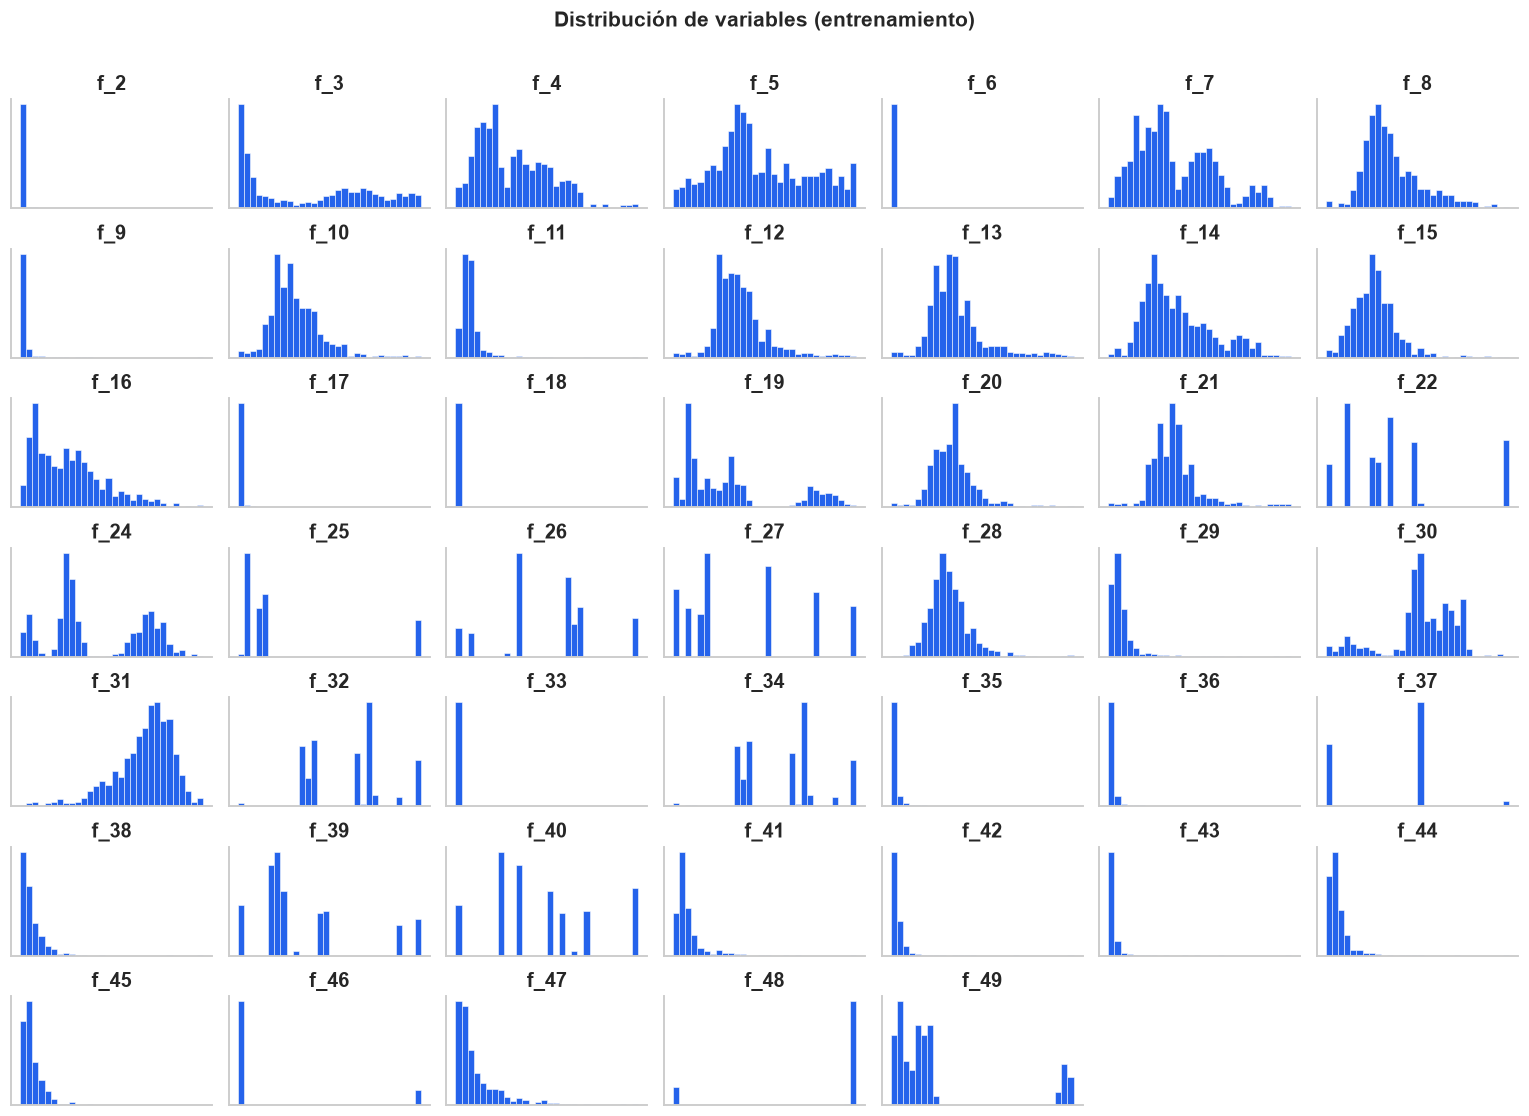

In [121]:
axes = X_train.hist(
    figsize=(14, 10),
    bins=30,
    color=PLOT_COLORS["primary"],
    edgecolor="white",
    linewidth=0.35,
    grid=False,
)

for axis in axes.flatten():
    axis.set_xlabel("")
    axis.set_ylabel("")
    axis.set_xticklabels([])
    axis.set_yticklabels([])
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

plt.suptitle(
    "Distribución de variables (entrenamiento)", 
    y=1.01,
    fontsize=14,
    fontweight="semibold"
)

plt.tight_layout()
plt.show()

In [122]:
display(X_train.info())

<class 'pandas.DataFrame'>
Index: 659 entries, 433 to 625
Data columns (total 47 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   f_2     659 non-null    int64  
 1   f_3     659 non-null    float64
 2   f_4     659 non-null    float64
 3   f_5     659 non-null    int64  
 4   f_6     659 non-null    float64
 5   f_7     659 non-null    float64
 6   f_8     659 non-null    float64
 7   f_9     659 non-null    float64
 8   f_10    659 non-null    float64
 9   f_11    659 non-null    float64
 10  f_12    659 non-null    float64
 11  f_13    659 non-null    float64
 12  f_14    659 non-null    float64
 13  f_15    659 non-null    float64
 14  f_16    659 non-null    float64
 15  f_17    659 non-null    float64
 16  f_18    659 non-null    float64
 17  f_19    659 non-null    float64
 18  f_20    659 non-null    float64
 19  f_21    659 non-null    float64
 20  f_22    659 non-null    float64
 21  f_24    659 non-null    float64
 22  f_25    659 non-

None

## 5. Feature Analysis


### 5.1 Feature Profile and Skewness


In [123]:
feature_profile = pd.DataFrame(
    {
        "skewness": X_train.skew(),
        "std": X_train.std(),
        "min": X_train.min(),
        "max": X_train.max(),
        "n_unique": X_train.nunique(),
    }
)

In [124]:
n_features = len(feature_profile)
n_highly_skewed = int((feature_profile["skewness"].abs() > 1).sum())
n_with_negatives = int((feature_profile["min"] <= 0).sum())
n_with_zeros_or_negatives = int((feature_profile["min"] <= 0).sum())
scale_ratio = feature_profile["std"].max() / feature_profile["std"].min()

In [125]:
print(f"Variables: {n_features}")
print(
    f"Variables con sesgo alto (|skew| > 1): {n_highly_skewed} ({n_highly_skewed / n_features:.0%})"
)
print(f"Variables con valores negativos: {n_with_negatives}")
print(f"Variables con valores cero o negativos: {n_with_zeros_or_negatives}")
print(f"Razón entre la mayor y la menor desviación estándar: {scale_ratio:,.0f}")
print(f"Valores faltantes en entrenamiento: {int(X_train.isna().sum().sum())}")

Variables: 47
Variables con sesgo alto (|skew| > 1): 33 (70%)
Variables con valores negativos: 15
Variables con valores cero o negativos: 15
Razón entre la mayor y la menor desviación estándar: 784,443,741
Valores faltantes en entrenamiento: 0


In [126]:
feature_profile.sort_values("skewness", key=np.abs, ascending=False).head(10)

,skewness,std,min,max,n_unique
f_18,21.1487,168.9711,1.9600,"4,061.1500",592
f_33,18.1088,0.0479,0.0000,0.8700,3
f_17,16.6238,278.3014,4.8200,"6,058.2300",633
f_6,12.5305,"4,158,159.0137","71,718.0000","71,315,000.0000",301
f_2,11.3953,"1,911.4586",10.0000,"28,526.0000",243
f_43,10.4542,556.0402,0.0000,"9,593.4800",470
f_9,10.2743,"8,960.9133",704.0000,"160,740.0000",448
f_36,9.4391,"5,656.1155",360.0000,"95,310.0000",96
f_35,9.1350,103.0699,3.0000,"1,695.0000",125
f_42,8.3927,735.0065,0.0000,"11,500.0000",184


### 5.2 Correlation


In [127]:
CORRELATION_THRESHOLD = 0.9

In [128]:
correlation = X_train.corr()
upper_triangle = correlation.where(
  np.triu(np.ones(correlation.shape, dtype=bool), k=1)
)

In [129]:
high_correlation_pairs = (
    upper_triangle.stack()
    .rename("correlation")
    .loc[lambda s: s.abs() > CORRELATION_THRESHOLD]
    .sort_values(key=np.abs, ascending=False)
)

display(high_correlation_pairs)

f_35  f_36    0.9992
f_32  f_34    0.9973
f_25  f_48   -0.9904
      f_49    0.9866
f_9   f_36    0.9841
      f_35    0.9821
f_42  f_43    0.9803
f_48  f_49   -0.9741
f_17  f_18    0.9692
f_2   f_6     0.9618
f_13  f_21    0.9562
f_12  f_21    0.9522
      f_13    0.9508
      f_20    0.9464
f_39  f_40    0.9407
f_20  f_21    0.9366
f_14  f_16    0.9248
f_42  f_44    0.9213
f_24  f_32   -0.9202
      f_34   -0.9200
f_22  f_49    0.9170
      f_25    0.9166
f_6   f_9     0.9081
f_7   f_24    0.9057
f_30  f_49   -0.9008
Name: correlation, dtype: float64

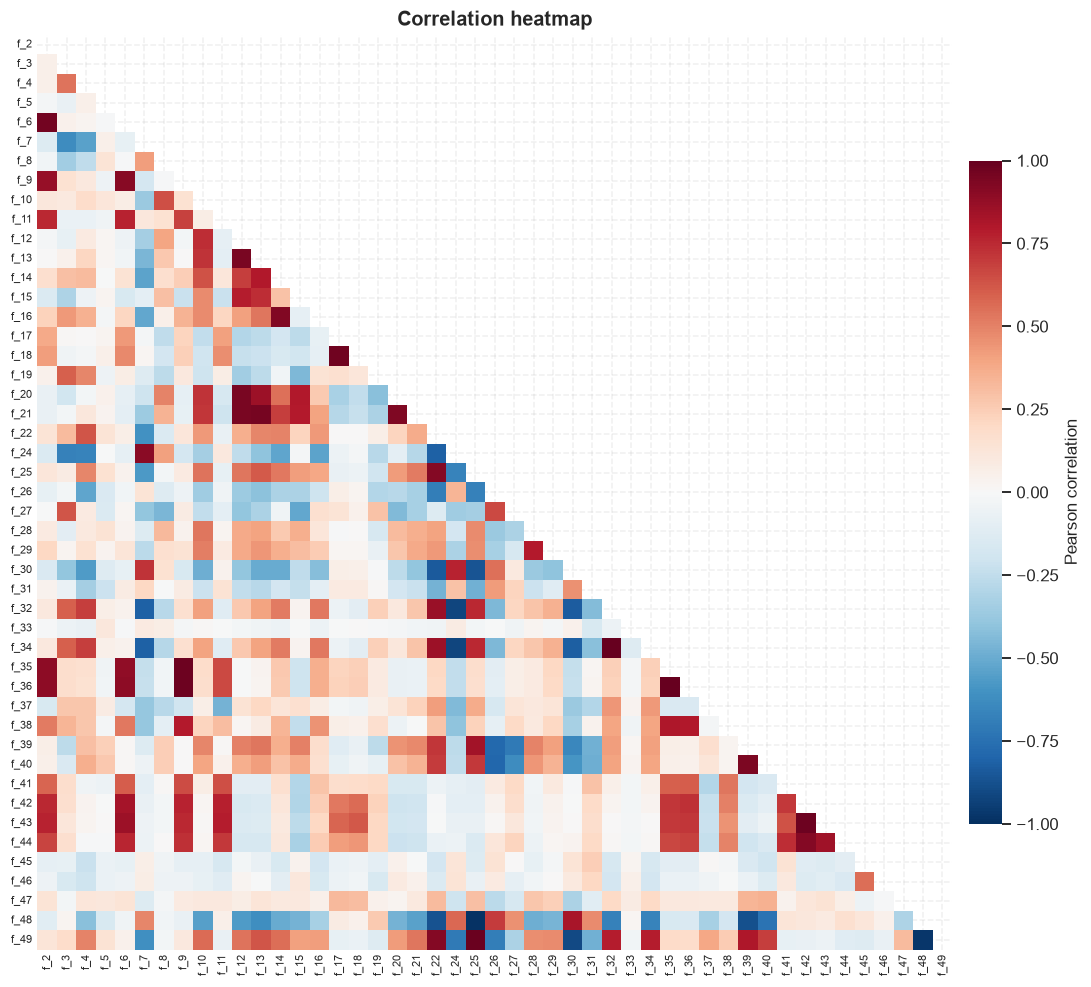

In [130]:
mask = np.triu(np.ones_like(correlation, dtype=bool))

fig, ax = plt.subplots(figsize=(10.5, 9))
sns.heatmap(
    correlation,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={
        "label": "Pearson correlation",
        "shrink": 0.72,
        "pad": 0.015,
    },
    ax=ax,
)

ax.set_title("Correlation heatmap")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", labelsize=7.5, length=0)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### 5.3 Class Separation


In [131]:
univariate_auc = X_train.apply(lambda col: roc_auc_score(y_train, col))
univariable_sepration = (
    univariate_auc.sub(0.5).abs().add(0.5).sort_values(ascending=False)
)

display(univariable_sepration)

f_47   0.8633
f_27   0.6583
f_28   0.6569
f_11   0.6515
f_39   0.6361
f_40   0.6327
f_48   0.6315
f_30   0.6284
f_6    0.6208
f_2    0.6134
f_29   0.6077
f_5    0.6062
f_26   0.6054
f_41   0.6023
f_37   0.5966
f_9    0.5960
f_25   0.5959
f_43   0.5880
f_14   0.5824
f_4    0.5781
f_13   0.5772
f_42   0.5702
f_22   0.5679
f_16   0.5655
f_35   0.5583
f_24   0.5581
f_12   0.5520
f_49   0.5518
f_36   0.5492
f_15   0.5453
f_34   0.5442
f_32   0.5433
f_38   0.5422
f_8    0.5400
f_31   0.5376
f_17   0.5345
f_46   0.5275
f_20   0.5244
f_10   0.5219
f_3    0.5218
f_21   0.5168
f_45   0.5137
f_19   0.5120
f_18   0.5075
f_44   0.5069
f_7    0.5033
f_33   0.5024
dtype: float64

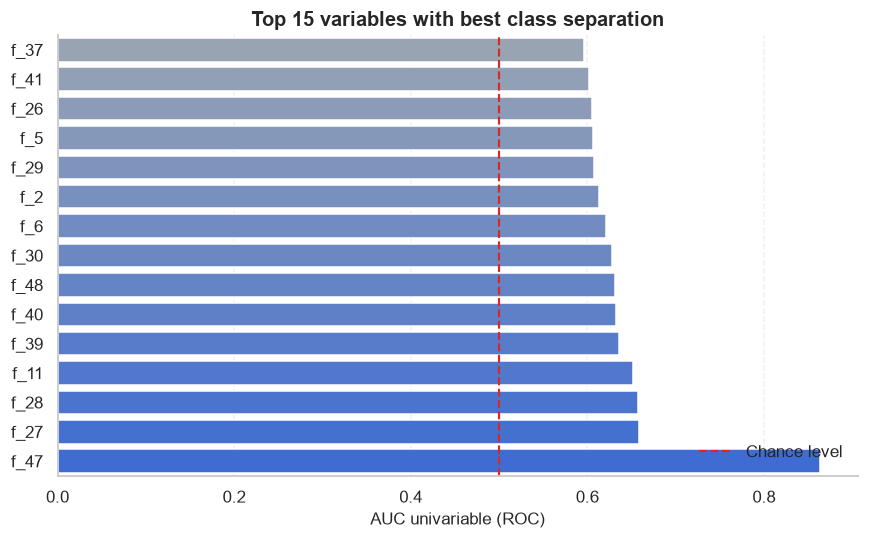

In [132]:
plot_data = univariable_sepration.head(15).sort_values()
palette = sns.color_palette("blend:#94A3B8,#2563EB", n_colors=len(plot_data))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    x=plot_data.to_numpy(),
    y=plot_data.index.astype(str),
    hue=plot_data.index.astype(str),
    palette=palette,
    legend=False,
    ax=ax,
)

ax.axvline(
    0.5, 
    color=PLOT_COLORS["danger"], 
    linestyle="--", 
    linewidth=1.4, 
    label="Chance level"
)

ax.set_xlabel("AUC univariable (ROC)")
ax.set_ylabel("")
ax.set_title("Top 15 variables with best class separation")
ax.legend(loc="lower right")
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 6. Preprocessing Pipeline


In [133]:
numeric_pipeline = Pipeline(
    steps=[
        ("mean_imputer", SimpleImputer(strategy="mean")),
        ("yeo_johnson_transformer", PowerTransformer(method="yeo-johnson")),
        ("standard_scaler", StandardScaler()),
    ]
)

numeric_columns = X_train.columns

In [134]:
column_transformer = ColumnTransformer(
    transformers=[("numeric", numeric_pipeline, numeric_columns)],
    remainder="passthrough",
)

### 6.1 Effect of Yeo-Johnson on Skewness


In [135]:
X_train_transformed = pd.DataFrame(
    clone(column_transformer).fit_transform(X_train),
    columns=numeric_columns,
    index=X_train.index,
)

In [136]:
skew_comparison = pd.DataFrame(
    {
        "Original": X_train.skew().abs(),
        "Yeo-Johnson + StandardScaler": X_train_transformed.skew().abs(),
    }
)

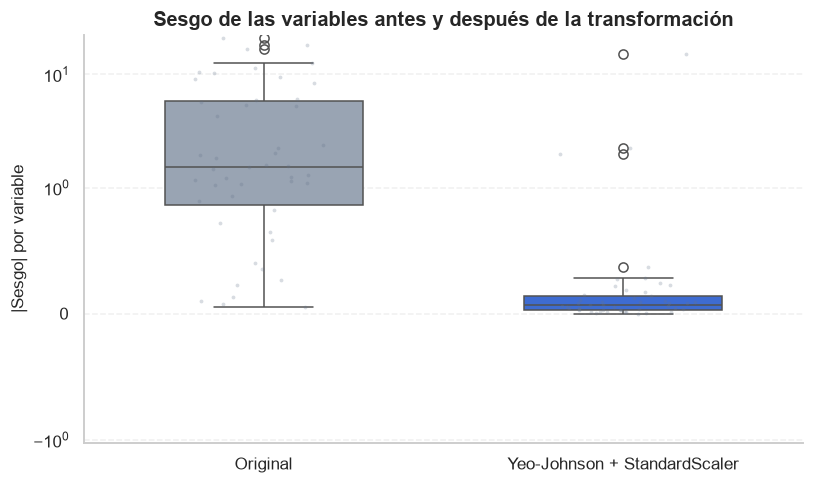

In [137]:
skew_long = skew_comparison.melt(var_name="Transformación", value_name="|Sesgo|")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.boxplot(
    data=skew_long,
    x="Transformación",
    y="|Sesgo|",
    hue="Transformación",
    palette=["#94A3B8", PLOT_COLORS["primary"]],
    width=0.55,
    legend=False,
    ax=ax,
)

sns.stripplot(
    data=skew_long,
    x="Transformación",
    y="|Sesgo|",
    color=PLOT_COLORS["muted"],
    alpha=0.25,
    size=2.5,
    jitter=0.2,
    ax=ax,
)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("")
ax.set_ylabel("|Sesgo| por variable")
ax.set_title("Sesgo de las variables antes y después de la transformación")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [138]:
skew_comparison.describe().loc[["mean", "50%", "max"]]

,Original,Yeo-Johnson + StandardScaler
mean,4.0945,0.5021
50%,1.5162,0.0678
max,21.1487,15.3031


### 6.2 G-Mean Scorer


In [139]:
gmean_scorer = make_scorer(geometric_mean_score)

### 6.3 Dummy Classifier Exploration


In [140]:
DUMMY_STRATEGIES = ("most_frequent", "prior", "stratified", "uniform")

In [141]:
N_SPLITS_OPTIONS = (2, 3, 5, 7, 10)

In [142]:
n_train_positives = int(y_train.sum())
exploration_rows = []

for strategy in DUMMY_STRATEGIES:
    for n_splits in N_SPLITS_OPTIONS:
        exploration_cv = RepeatedStratifiedKFold(
            n_splits=n_splits, n_repeats=3, random_state=7
        )

        dummy_pipeline = Pipeline(
            steps=[
                ("ct", column_transformer),
                ("dummy", DummyClassifier(strategy=strategy, random_state=7)),
            ]
        )

        exploration_scores = cross_val_score(
            dummy_pipeline,
            X_train,
            y_train,
            scoring=gmean_scorer,
            cv=exploration_cv,
            n_jobs=-1,
        )

        exploration_rows.append(
            {
                "strategy": strategy,
                "n_splits": n_splits,
                "positives_per_fold": n_train_positives / n_splits,
                "gmean": exploration_scores.mean(),
                "std": exploration_scores.std(),
            }
        )

In [143]:
dummy_exploration = pd.DataFrame(exploration_rows)
print(f"Positive cases in training: {n_train_positives}")

Positive cases in training: 28


In [144]:
dummy_exploration.pivot(
    index="n_splits", columns="strategy", values=["gmean", "std"]
).round(3)

display(dummy_exploration.sort_values("gmean", ascending=False).head(10))

,strategy,n_splits,positives_per_fold,gmean,std
16,uniform,3,9.3333,0.5506,0.0669
15,uniform,2,14.0000,0.5132,0.0531
17,uniform,5,5.6000,0.5081,0.1367
19,uniform,10,2.8000,0.4927,0.1635
18,uniform,7,4.0000,0.4891,0.0813
10,stratified,2,14.0000,0.1061,0.1533
11,stratified,3,9.3333,0.0713,0.1335
12,stratified,5,5.6000,0.0540,0.1377
3,most_frequent,7,4.0000,0.0000,0.0000
2,most_frequent,5,5.6000,0.0000,0.0000


## 7. G-Mean Baseline


In [145]:
best_strategy = "uniform"
best_n_splits = 5

In [146]:
cv = RepeatedStratifiedKFold(
  n_splits=best_n_splits, n_repeats=3, random_state=7
)

In [147]:
dummy_model = DummyClassifier(strategy=best_strategy, random_state=7)

In [148]:
dummy_pipeline = Pipeline(
  steps=[
    ("ct", column_transformer), 
    ("dummy", dummy_model)
  ]
)

In [149]:
scores = cross_val_score(
    dummy_pipeline, X_train, y_train, scoring=gmean_scorer, cv=cv, n_jobs=-1
)

In [150]:
BASELINE_GMEAN = scores.mean()
print(f"Baseline G-Mean: {BASELINE_GMEAN:.3f}")

Baseline G-Mean: 0.508


## 8. Accuracy Baseline and Confusion Matrix


In [151]:
naive_accuracy_pipeline = Pipeline(
    steps=[
        ("ct", column_transformer),
        ("dummy", DummyClassifier(strategy="most_frequent")),
    ]
)

In [152]:
native_accuracy_scores = cross_val_score(
    naive_accuracy_pipeline, 
    X_train, 
    y_train, 
    scoring="accuracy", 
    cv=cv, 
    n_jobs=-1
)

In [153]:
BASELINE_ACCURACY = native_accuracy_scores.mean()

In [154]:
y_train_naive = cross_val_predict(
    naive_accuracy_pipeline,
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=best_n_splits, shuffle=True, random_state=7),
)

In [155]:
naive_confusion = confusion_matrix(y_train, y_train_naive)

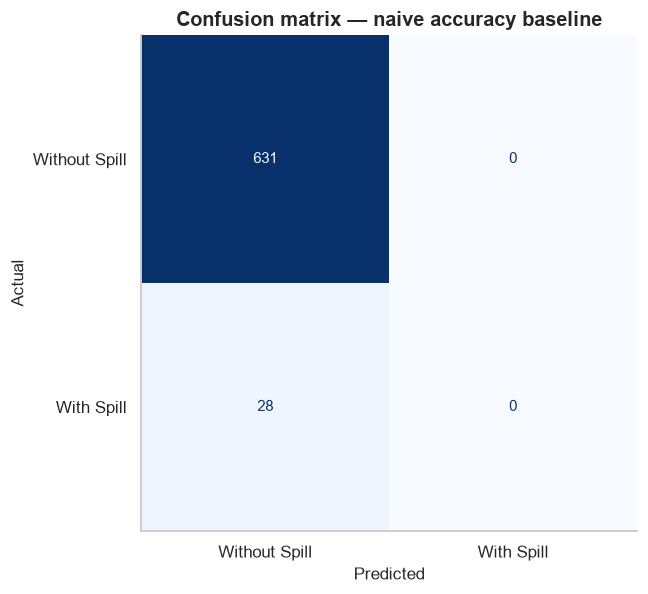

Accuracy on CV predictions: 0.9575
Baseline accuracy (CV mean): 0.9575


In [156]:
fig, ax = plt.subplots(figsize=(6, 5.5))
ConfusionMatrixDisplay(
    confusion_matrix=naive_confusion,
    display_labels=["Without Spill", "With Spill"],
).plot(
    ax=ax,
    cmap=sns.color_palette("Blues", as_cmap=True),
    colorbar=False,
)

ax.set_title("Confusion matrix — naive accuracy baseline")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.grid(False)
sns.despine(left=False, bottom=False)
plt.tight_layout()
plt.show()

print(
    f"Accuracy on CV predictions: {accuracy_score(y_train, y_train_naive):.4f}"
)
print(f"Baseline accuracy (CV mean): {BASELINE_ACCURACY:.4f}")

## 9. Model Selection


In [157]:
def get_baseline_models() -> dict[str, BaseEstimator]:
    """
    Return the five models of the activity with their default settings
    """

    return {
        "LR": LogisticRegression(C=np.inf, max_iter=2000, random_state=1),
        "LASSO": LogisticRegression(
            l1_ratio=1, solver="liblinear", max_iter=2000, random_state=1
        ),
        "RIDGE": LogisticRegression(l1_ratio=0, max_iter=2000, random_state=1),
        "EN": LogisticRegression(
            l1_ratio=0.5, solver="saga", max_iter=5000, random_state=1
        ),
        "kNN": KNeighborsClassifier(n_neighbors=5),
    }

In [158]:
def evaluate_models(
    models: dict[str, BaseEstimator],
    X: pd.DataFrame,
    Y: pd.Series,
    scoring: dict[str, object],
    cv: RepeatedStratifiedKFold,
) -> dict[str, dict[str, np.ndarray]]:
    """
    Cross-validate each model inside the preprocessing
    pipeline and collect its fold scores.
    """

    results = {}
    for name, model in models.items():
        pipeline = Pipeline(steps=[("ct", column_transformer), ("model", model)])

        fold_scores = cross_validate(
            pipeline, X, np.ravel(Y), scoring=scoring, cv=cv, n_jobs=-1
        )

        results[name] = {metric: fold_scores[f"test_{metric}"] for metric in scoring}

    return results

In [159]:
def summarize_results(results: dict[str, dict[str, np.ndarray]]) -> pd.DataFrame:
    """
    Return the mean and standard deviation of every metric for every model.
    """

    return pd.DataFrame(
        {
            (metric, statistic): {
                name: getattr(np, f"nan{statistic}")(metrics[metric])
                for name, metrics in results.items()
            }
            for metric in next(iter(results.values()))
            for statistic in ("mean", "std")
        }
    )

In [160]:
def plot_score_boxplots(
    results: dict[str, dict[str, np.ndarray]],
    metric: str,
    title: str,
    baseline: float | None = None,
) -> None:
    """
    Draw one seaborn boxplot per model for the given metric, with an optional baseline.
    """

    rows = [
        {"model": name, "score": float(value)}
        for name, metrics in results.items()
        for value in metrics[metric]
    ]
    plot_df = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    sns.boxplot(
        data=plot_df,
        x="model",
        y="score",
        hue="model",
        palette="deep",
        width=0.55,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": PLOT_COLORS["danger"],
            "markersize": 6,
        },
        legend=False,
        ax=ax,
    )
    sns.stripplot(
        data=plot_df,
        x="model",
        y="score",
        color=PLOT_COLORS["muted"],
        alpha=0.35,
        size=3,
        jitter=0.18,
        ax=ax,
    )

    if baseline is not None:
        ax.axhline(
            baseline,
            color=PLOT_COLORS["danger"],
            linestyle="--",
            linewidth=1.5,
            label=f"Modelo base ({baseline:.3f})",
        )
        ax.legend(loc="lower right")

    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.set_title(title)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

In [161]:
SCORING = {"accuracy": "accuracy", "gmean": gmean_scorer}

In [162]:
cv_models = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
baseline_results = evaluate_models(
    get_baseline_models(), X_trainval, y_trainval, SCORING, cv_models
)

In [163]:
print("Validation Results:")
for name, metrics in baseline_results.items():
    print(f"{name}: {metrics['gmean'].mean():.3f} ± {metrics['gmean'].std():.3f}")

Validation Results:
LR: 0.652 ± 0.123
LASSO: 0.501 ± 0.158
RIDGE: 0.541 ± 0.113
EN: 0.540 ± 0.109
kNN: 0.174 ± 0.187


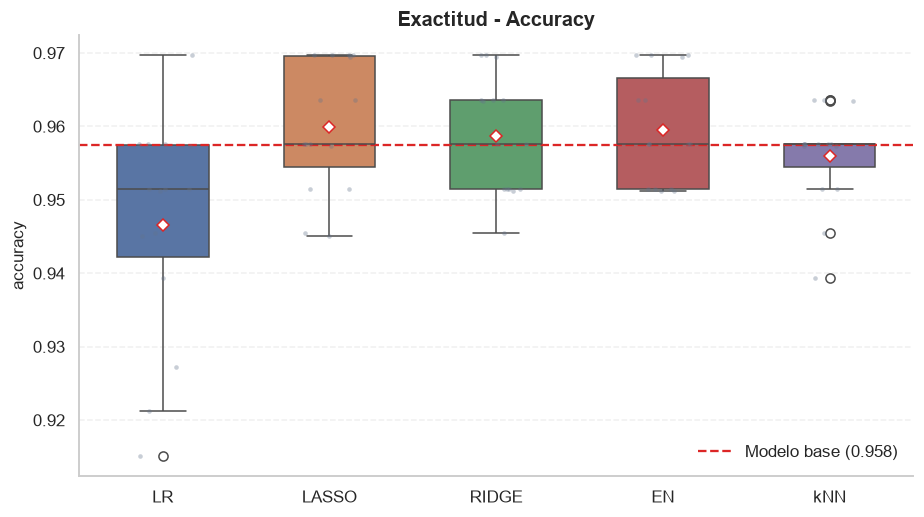

In [164]:
plot_score_boxplots(
    baseline_results, "accuracy", "Exactitud - Accuracy", baseline=BASELINE_ACCURACY
)

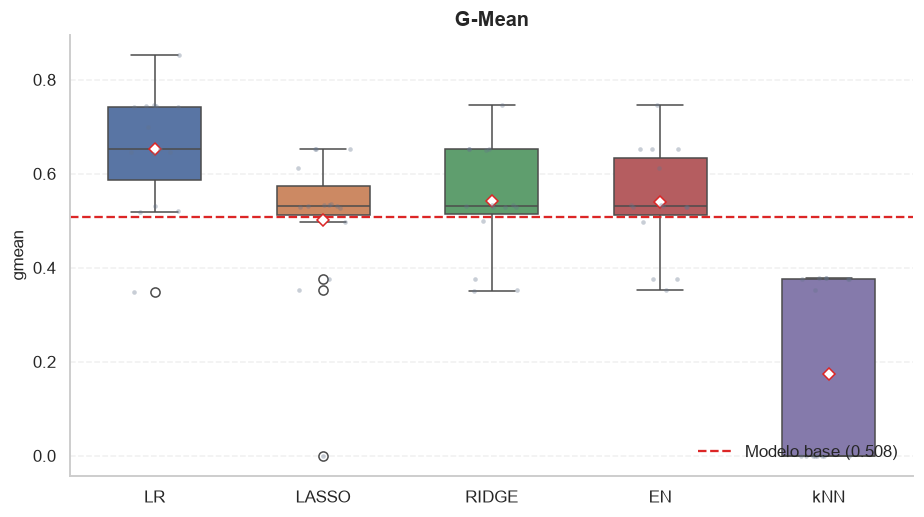

In [165]:
plot_score_boxplots(
  baseline_results, 
  "gmean", 
  "G-Mean", 
  baseline=BASELINE_GMEAN
)

## 10. Underfitting Analysis


In [166]:
baseline_summary = summarize_results(baseline_results)
underfit_table = pd.DataFrame(
    {
        "accuracy_mean": baseline_summary[("accuracy", "mean")],
        "accuracy_baseline": BASELINE_ACCURACY,
        "underfit_accuracy": baseline_summary[("accuracy", "mean")]
        <= BASELINE_ACCURACY,
        "gmean_mean": baseline_summary[("gmean", "mean")],
        "gmean_baseline": BASELINE_GMEAN,
        "underfit_gmean": baseline_summary[("gmean", "mean")] <= BASELINE_GMEAN,
    }
)

display(underfit_table)

,accuracy_mean,accuracy_baseline,underfit_accuracy,gmean_mean,gmean_baseline,underfit_gmean
LR,0.9466,0.9575,True,0.6517,0.5081,False
LASSO,0.9599,0.9575,False,0.5011,0.5081,True
RIDGE,0.9587,0.9575,False,0.5413,0.5081,False
EN,0.9595,0.9575,False,0.5403,0.5081,False
kNN,0.9559,0.9575,True,0.1744,0.5081,True


## 11. Hyperparameter Tuning


In [167]:
C_VALUES = np.logspace(-3, 2, 11)

In [168]:
SEARCH_SPACES: dict[str, tuple[BaseEstimator, dict[str, list]]] = {
    "LR": (
        LogisticRegression(C=np.inf, max_iter=10_000, random_state=1),
        {"model__class_weight": [None, "balanced"]},
    ),
    "LASSO": (
        LogisticRegression(
            l1_ratio=1, solver="liblinear", max_iter=10_000, random_state=1
        ),
        {"model__C": list(C_VALUES), "model__class_weight": [None, "balanced"]},
    ),
    "RIDGE": (
        LogisticRegression(l1_ratio=0, max_iter=10_000, random_state=1),
        {"model__C": list(C_VALUES), "model__class_weight": [None, "balanced"]},
    ),
    "EN": (
        LogisticRegression(solver="saga", max_iter=20_000, random_state=1),
        {
            "model__C": list(C_VALUES),
            "model__l1_ratio": [0.25, 0.5, 0.75],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "kNN": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
        },
    ),
}

In [169]:
cache_dir = mkdtemp(prefix="oil_spill_cache_")

In [170]:
searches: dict[str, GridSearchCV] = {}
for name, (estimator, param_grid) in SEARCH_SPACES.items():
    search_pipeline = Pipeline(
        steps=[("ct", column_transformer), ("model", estimator)], memory=cache_dir
    )
    searches[name] = GridSearchCV(
        search_pipeline, param_grid, scoring=gmean_scorer, cv=cv_models, n_jobs=-1
    ).fit(X_trainval, np.ravel(y_trainval))

In [171]:
shutil.rmtree(cache_dir, ignore_errors=True)

In [172]:
best_params_table = pd.DataFrame(
    {
        name: {
            "gmean_cv": search.best_score_,
            "mejores_hiperparámetros": {
                key.removeprefix("model__"): value
                for key, value in search.best_params_.items()
            },
        }
        for name, search in searches.items()
    }
).T
with pd.option_context("display.max_colwidth", None):
    display(best_params_table)

,gmean_cv,mejores_hiperparámetros
LR,0.7588,{'class_weight': 'balanced'}
LASSO,0.8373,"{'C': 0.1, 'class_weight': 'balanced'}"
RIDGE,0.8173,"{'C': 0.01, 'class_weight': 'balanced'}"
EN,0.8427,"{'C': 0.03162277660168379, 'class_weight': 'balanced', 'l1_ratio': 0.75}"
kNN,0.4968,"{'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}"


In [173]:
def get_tuned_models(
    fitted_searches: dict[str, GridSearchCV],
) -> dict[str, BaseEstimator]:
    """
    Return the same five models, configured with the best hyperparameters found.
    """

    return {
        name: clone(search.best_estimator_.named_steps["model"])
        for name, search in fitted_searches.items()
    }

In [174]:
tuned_results = evaluate_models(
    get_tuned_models(searches),
    X_trainval,
    y_trainval,
    {"gmean": gmean_scorer},
    cv_models,
)

In [175]:
for name, metrics in tuned_results.items():
    print(f"{name}: {metrics['gmean'].mean():.3f} ± {metrics['gmean'].std():.3f}")

LR: 0.759 ± 0.123
LASSO: 0.837 ± 0.052
RIDGE: 0.817 ± 0.106
EN: 0.843 ± 0.058
kNN: 0.497 ± 0.101


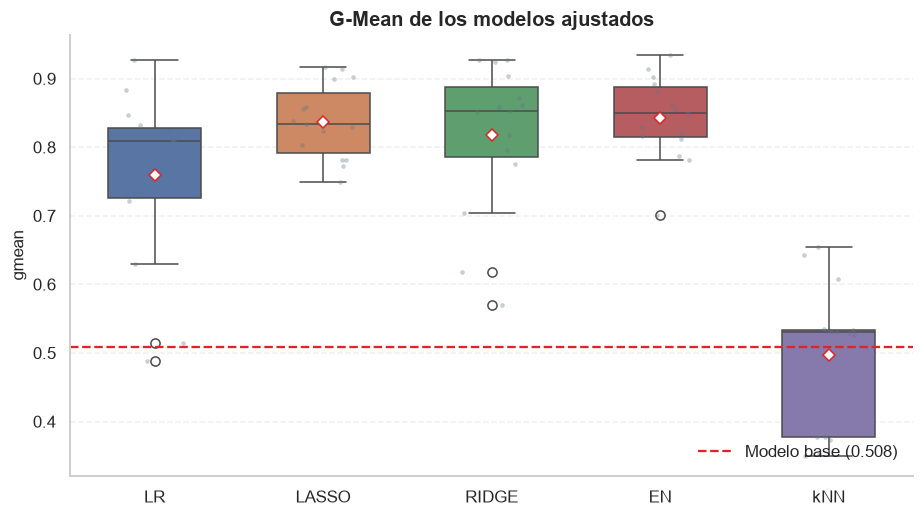

In [176]:
plot_score_boxplots(
    tuned_results, "gmean", "G-Mean de los modelos ajustados", baseline=BASELINE_GMEAN
)

In [177]:
tuning_gain = pd.DataFrame(
    {
        "gmean_default": summarize_results(baseline_results)[("gmean", "mean")],
        "gmean_tuned": summarize_results(tuned_results)[("gmean", "mean")],
        "gmean_tuned_std": summarize_results(tuned_results)[("gmean", "std")],
    }
).assign(gain=lambda table: table["gmean_tuned"] - table["gmean_default"])

display(tuning_gain)

,gmean_default,gmean_tuned,gmean_tuned_std,gain
LR,0.6517,0.7588,0.1226,0.1071
LASSO,0.5011,0.8373,0.0523,0.3362
RIDGE,0.5413,0.8173,0.1058,0.2760
EN,0.5403,0.8427,0.0582,0.3024
kNN,0.1744,0.4968,0.1011,0.3224


## 12. Final Model Selection


In [178]:
LOGISTIC_FAMILIES = {
    "LASSO": {"l1_ratio": 1, "solver": "liblinear"},
    "RIDGE": {"l1_ratio": 0, "solver": "lbfgs"},
    "EN": {
        "l1_ratio": searches["EN"].best_params_["model__l1_ratio"],
        "solver": "saga",
    },
}

In [179]:
MAX_TRAIN_VAL_GAP = 0.03
C_SWEEP = np.logspace(-4, 1, 41)

In [180]:
tuned_gmean = summarize_results(tuned_results)[("gmean", "mean")]
best_family = tuned_gmean.loc[list(LOGISTIC_FAMILIES)].idxmax()
family_params = LOGISTIC_FAMILIES[best_family]

In [181]:
def build_logistic(c_value: float) -> LogisticRegression:
    """
    Return the selected logistic family with the given inverse regularization
    strength.
    """

    return LogisticRegression(
        C=c_value,
        class_weight="balanced",
        max_iter=20_000,
        random_state=1,
        **family_params,
    )

In [182]:
preprocessor = clone(column_transformer).fit(X_train)
X_train_prepared = preprocessor.transform(X_train)
X_val_prepared = preprocessor.transform(X_val)

In [183]:
sweep_rows = []
for c_value in C_SWEEP:
    candidate = build_logistic(c_value).fit(X_train_prepared, y_train)
    sweep_rows.append(
        {
            "C": c_value,
            "gmean_train": geometric_mean_score(
                y_train, candidate.predict(X_train_prepared)
            ),
            "gmean_val": geometric_mean_score(y_val, candidate.predict(X_val_prepared)),
        }
    )

In [184]:
c_sweep = pd.DataFrame(sweep_rows).assign(
    gap=lambda table: (table["gmean_train"] - table["gmean_val"]).abs()
)

In [185]:
eligible = c_sweep[c_sweep["gap"] <= MAX_TRAIN_VAL_GAP]
best_c = float(
    eligible.sort_values(["gmean_val", "C"], ascending=[False, True])["C"].iloc[0]
)

In [186]:
best_model = Pipeline(
    steps=[("ct", column_transformer), ("model", build_logistic(best_c))]
).fit(X_train, y_train)

In [187]:
y_train_hat = best_model.predict(X_train)
y_val_hat = best_model.predict(X_val)

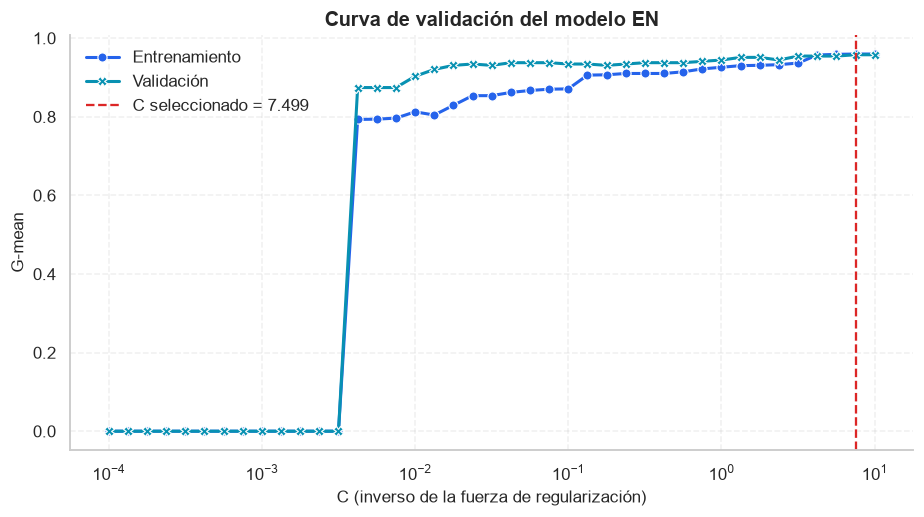

In [188]:
curve_long = c_sweep.melt(
    id_vars="C",
    value_vars=["gmean_train", "gmean_val"],
    var_name="conjunto",
    value_name="gmean",
).replace({"gmean_train": "Entrenamiento", "gmean_val": "Validación"})

fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.lineplot(
    data=curve_long,
    x="C",
    y="gmean",
    hue="conjunto",
    style="conjunto",
    markers=True,
    dashes=False,
    palette=[PLOT_COLORS["primary"], PLOT_COLORS["secondary"]],
    linewidth=2,
    ax=ax,
)

ax.axvline(
    best_c,
    color=PLOT_COLORS["danger"],
    linestyle="--",
    linewidth=1.5,
    label=f"C seleccionado = {best_c:.4g}",
)

ax.set_xscale("log")
ax.set_xlabel("C (inverso de la fuerza de regularización)")
ax.set_ylabel("G-mean")
ax.set_title(f"Curva de validación del modelo {best_family}")
ax.legend()
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

In [189]:
n_selected_features = int(np.count_nonzero(best_model.named_steps["model"].coef_))
print(f"Número de variables seleccionadas: {n_selected_features}")
print(f"Número de variables totales: {len(numeric_columns)}")
print(
    f"Porcentaje de variables seleccionadas: {n_selected_features / len(numeric_columns):.0%}"
)

Número de variables seleccionadas: 47
Número de variables totales: 47
Porcentaje de variables seleccionadas: 100%


### 12.1 Selected Features and Coefficients


In [190]:
coefficients = pd.Series(
    best_model.named_steps["model"].coef_.ravel(),
    index=numeric_columns,
    name="coefficient",
)
nonzero_coefficients = coefficients.loc[lambda s: s != 0].sort_values(key=np.abs)
display(nonzero_coefficients.to_frame().assign(abs_coefficient=lambda df: df["coefficient"].abs()))

,coefficient,abs_coefficient
f_37,-0.0176,0.0176
f_18,-0.0366,0.0366
f_45,0.1328,0.1328
f_42,-0.1613,0.1613
f_7,0.2138,0.2138
f_34,0.2456,0.2456
f_33,-0.2509,0.2509
f_19,-0.3033,0.3033
f_11,-0.3411,0.3411
f_41,-0.3497,0.3497


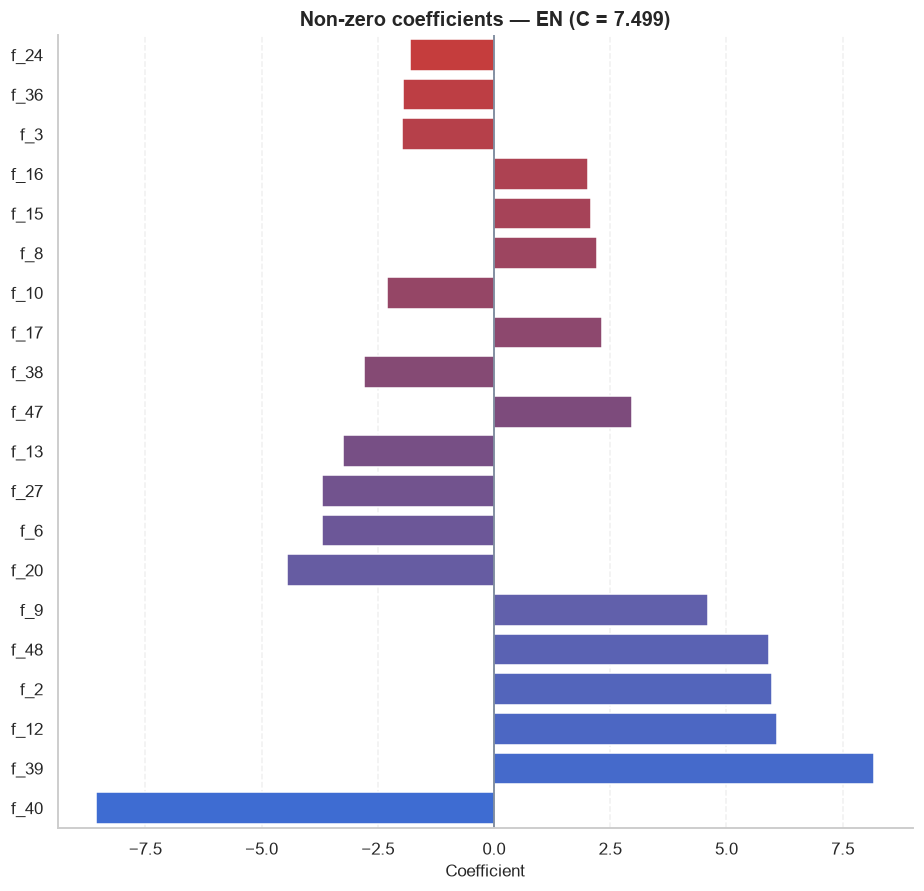

In [191]:
plot_coefficients = (
    nonzero_coefficients.tail(20)
    if len(nonzero_coefficients) > 20
    else nonzero_coefficients
)

fig, ax = plt.subplots(figsize=(8.5, max(4.0, 0.35 * len(plot_coefficients) + 1.2)))
sns.barplot(
    x=plot_coefficients.to_numpy(),
    y=plot_coefficients.index.astype(str),
    hue=plot_coefficients.index.astype(str),
    palette=sns.color_palette(
        "blend:#DC2626,#2563EB", n_colors=len(plot_coefficients)
    ),
    legend=False,
    ax=ax,
)
ax.axvline(0, color=PLOT_COLORS["muted"], linewidth=1)
ax.set_xlabel("Coefficient")
ax.set_ylabel("")
ax.set_title(f"Non-zero coefficients — {best_family} (C = {best_c:.4g})")
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 13. Model Metrics


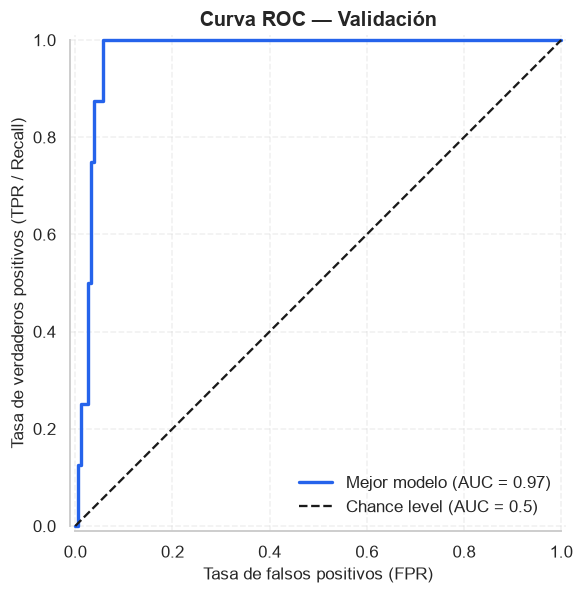

In [192]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
RocCurveDisplay.from_estimator(
    best_model,
    X_val,
    y_val,
    name="Mejor modelo",
    plot_chance_level=True,
    ax=ax,
    curve_kwargs={"color": PLOT_COLORS["primary"], "linewidth": 2.2},
    despine=True,
)

ax.set_title("Curva ROC — Validación")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (TPR / Recall)")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

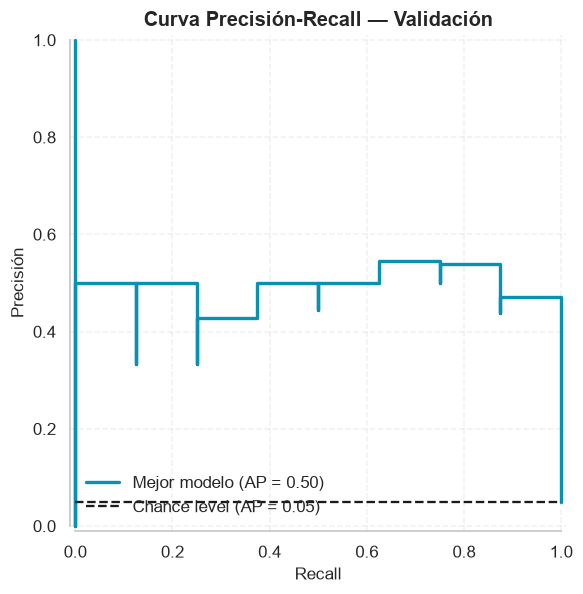

Prevalencia de la clase positiva en validación: 0.0485


In [193]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
PrecisionRecallDisplay.from_estimator(
    best_model,
    X_val,
    y_val,
    name="Mejor modelo",
    plot_chance_level=True,
    ax=ax,
    curve_kwargs={"color": PLOT_COLORS["secondary"], "linewidth": 2.2},
    despine=True,
)

ax.set_title("Curva Precisión-Recall — Validación")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
plt.tight_layout()
plt.show()

print(f"Prevalencia de la clase positiva en validación: {y_val.mean():.4f}")

In [194]:
print(f"Accuracy (validación): {accuracy_score(np.ravel(y_val), y_val_hat):.4f}")
print(
    classification_report_imbalanced(
        np.ravel(y_val),
        y_val_hat,
        target_names=["class 0:non-spill", "class 1:oil-spill"],
    )
)

Accuracy (validación): 0.9212
                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.92      1.00      0.96      0.96      0.91       157
class 1:oil-spill       0.38      1.00      0.92      0.55      0.96      0.92         8

      avg / total       0.97      0.92      1.00      0.94      0.96      0.91       165



## 14. Cost Function


In [195]:
COST_FALSE_NEGATIVE = 1_000_000
COST_FALSE_POSITIVE = 15_000
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.01), 2)

In [196]:
def expected_total_cost(
    y_true: np.ndarray,
    positive_proba: np.ndarray,
    thresholds: np.ndarray = THRESHOLDS,
    cost_fn: float = COST_FALSE_NEGATIVE,
    cost_fp: float = COST_FALSE_POSITIVE,
) -> pd.DataFrame:
    """
    Return the confusion counts and total error cost for every probability threshold.

    The comparison is vectorized: a (n_samples, n_thresholds) boolean matrix
    holds the prediction of every sample under every threshold, so no Python
    loop is needed.

    True positives and true negatives cost 0 USD.
    """

    is_positive = np.asarray(y_true, dtype=bool)[:, np.newaxis]
    predicted_positive = (
        np.asarray(positive_proba)[:, np.newaxis] >= thresholds[np.newaxis, :]
    )

    costs = pd.DataFrame(
        {
            "threshold": thresholds,
            "tn": (~predicted_positive & ~is_positive).sum(axis=0),
            "fp": (predicted_positive & ~is_positive).sum(axis=0),
            "fn": (~predicted_positive & is_positive).sum(axis=0),
            "tp": (predicted_positive & is_positive).sum(axis=0),
        }
    )

    costs["total_cost"] = costs["fn"] * cost_fn + costs["fp"] * cost_fp
    return costs

In [197]:
val_positive_proba = best_model.predict_proba(X_val)[:, 1]
cost_table = expected_total_cost(y_val, val_positive_proba)

In [198]:
min_cost = cost_table["total_cost"].min()
optimal_plateau = cost_table.loc[cost_table["total_cost"] == min_cost, "threshold"]

In [199]:
best_threshold = float(optimal_plateau.iloc[len(optimal_plateau) // 2])
default_cost = int(
    cost_table.loc[np.isclose(cost_table["threshold"], 0.5), "total_cost"].iloc[0]
)

In [200]:
print(f"Costo mínimo en validación: ${min_cost:,.0f} USD")
print(
    f"Umbrales que alcanzan ese mínimo: {optimal_plateau.min():.2f} a {optimal_plateau.max():.2f}"
)
print(f"Umbral óptimo seleccionado (centro del intervalo): {best_threshold:.2f}")
print(f"Costo con el umbral predeterminado 0.50: ${default_cost:,.0f} USD")
print(f"Ahorro al cambiar de umbral: ${default_cost - min_cost:,.0f} USD")

Costo mínimo en validación: $135,000 USD
Umbrales que alcanzan ese mínimo: 0.69 a 0.71
Umbral óptimo seleccionado (centro del intervalo): 0.70
Costo con el umbral predeterminado 0.50: $195,000 USD
Ahorro al cambiar de umbral: $60,000 USD


In [201]:
cost_table.iloc[::5].style.format(
    {"threshold": "{:.2f}", "total_cost": "${:,.0f}"}
).hide(axis="index")

threshold,tn,fp,fn,tp,total_cost
0.10,123,34,0,8,"$510,000"
0.15,128,29,0,8,"$435,000"
0.20,134,23,0,8,"$345,000"
0.25,140,17,0,8,"$255,000"
0.30,140,17,0,8,"$255,000"
0.35,141,16,0,8,"$240,000"
0.40,143,14,0,8,"$210,000"
0.45,143,14,0,8,"$210,000"
0.50,144,13,0,8,"$195,000"
0.55,144,13,0,8,"$195,000"


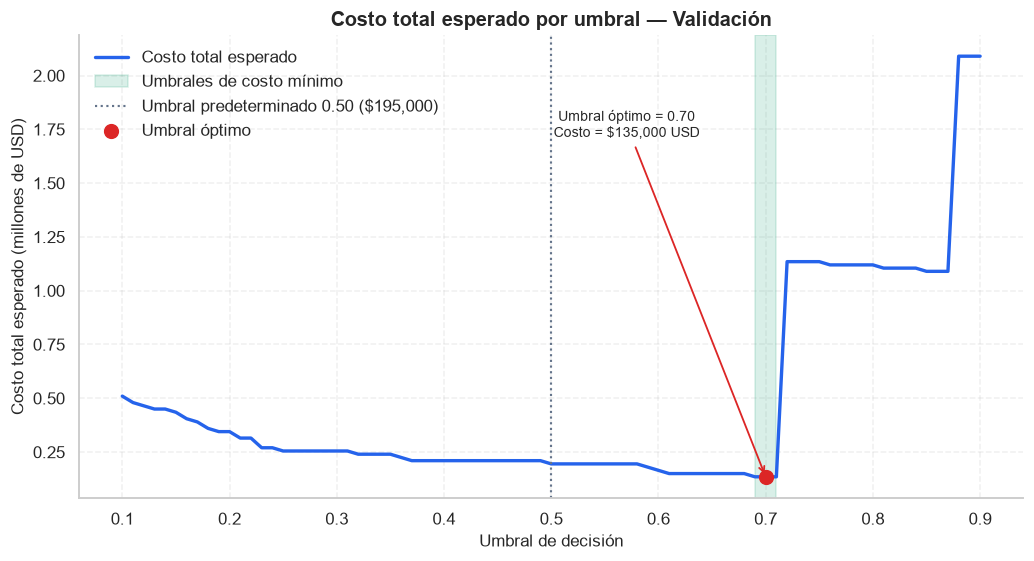

In [202]:
cost_plot = cost_table.assign(total_cost_m=lambda df: df["total_cost"] / 1e6)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
sns.lineplot(
    data=cost_plot,
    x="threshold",
    y="total_cost_m",
    color=PLOT_COLORS["primary"],
    linewidth=2.2,
    ax=ax,
    label="Costo total esperado",
)

ax.axvspan(
    optimal_plateau.min(),
    optimal_plateau.max(),
    color=PLOT_COLORS["success"],
    alpha=0.15,
    label="Umbrales de costo mínimo",
)

ax.axvline(
    0.5,
    color=PLOT_COLORS["muted"],
    linestyle=":",
    linewidth=1.4,
    label=f"Umbral predeterminado 0.50 (${default_cost:,.0f})",
)

ax.scatter(
    [best_threshold],
    [min_cost / 1e6],
    color=PLOT_COLORS["danger"],
    zorder=3,
    s=80,
    label="Umbral óptimo",
)

ax.annotate(
    f"Umbral óptimo = {best_threshold:.2f}\nCosto = ${min_cost:,.0f} USD",
    xy=(best_threshold, min_cost / 1e6),
    xytext=(0.58, 0.78),
    textcoords="axes fraction",
    ha="center",
    fontsize=9,
    arrowprops={"arrowstyle": "->", "color": PLOT_COLORS["danger"], "lw": 1.2},
)

ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Costo total esperado (millones de USD)")
ax.set_title("Costo total esperado por umbral — Validación")
ax.legend(loc="upper left")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 14.1 Threshold Comparison


In [203]:
threshold_cases = [("Predeterminado", 0.5), ("Óptimo", best_threshold)]

Predeterminado: umbral = 0.50 | accuracy = 0.9212 | G-mean = 0.9577
Matriz de confusión:
[[144  13]
 [  0   8]]

Óptimo: umbral = 0.70 | accuracy = 0.9455 | G-mean = 0.9709
Matriz de confusión:
[[148   9]
 [  0   8]]



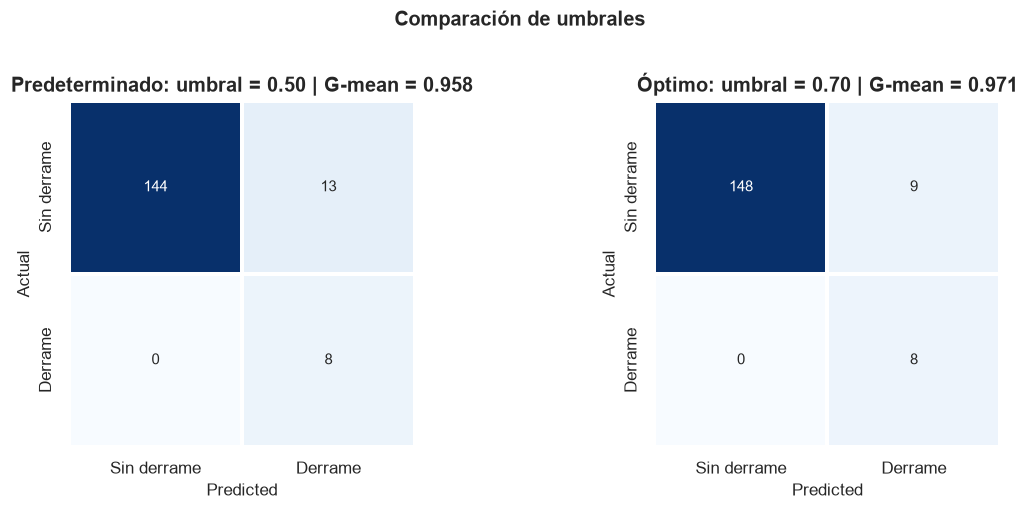

In [204]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
comparison_rows = []

for ax, (label, threshold) in zip(axes, threshold_cases):
    predictions = (val_positive_proba >= threshold).astype(int)
    matrix = confusion_matrix(y_val, predictions)
    tn, fp, fn, tp = matrix.ravel()
    gmean = geometric_mean_score(y_val, predictions)
    acc = accuracy_score(y_val, predictions)
    comparison_rows.append(
        {
            "caso": label,
            "umbral": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "accuracy": acc,
            "G-mean": gmean,
            "costo_total_usd": fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE,
        }
    )

    print(
        f"{label}: umbral = {threshold:.2f} | accuracy = {acc:.4f} | "
        f"G-mean = {gmean:.4f}\nMatriz de confusión:\n{matrix}\n"
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap=sns.color_palette("Blues", as_cmap=True),
        cbar=False,
        square=True,
        linewidths=1.5,
        linecolor="white",
        xticklabels=["Sin derrame", "Derrame"],
        yticklabels=["Sin derrame", "Derrame"],
        ax=ax,
    )
    ax.set_title(f"{label}: umbral = {threshold:.2f} | G-mean = {gmean:.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(
    "Comparación de umbrales", y=1.02, fontsize=13, fontweight="semibold"
)

plt.tight_layout()
plt.show()

In [205]:
pd.DataFrame(comparison_rows).style.format(
    {
        "umbral": "{:.2f}",
        "accuracy": "{:.4f}",
        "G-mean": "{:.4f}",
        "costo_total_usd": "${:,.0f}",
    }
).hide(axis="index")

caso,umbral,TN,FP,FN,TP,accuracy,G-mean,costo_total_usd
Predeterminado,0.50,144,13,0,8,0.9212,0.9577,"$195,000"
Óptimo,0.70,148,9,0,8,0.9455,0.9709,"$135,000"


## 15. Hold-out Test Evaluation


In [206]:
final_model = Pipeline(
    steps=[("ct", column_transformer), ("model", build_logistic(best_c))]
).fit(X_trainval, y_trainval)

In [207]:
test_positive_proba = final_model.predict_proba(X_test)[:, 1]
y_test_hat = (test_positive_proba >= best_threshold).astype(int)

In [208]:
test_matrix = confusion_matrix(y_test, y_test_hat)
tn, fp, fn, tp = test_matrix.ravel()
test_accuracy = accuracy_score(y_test, y_test_hat)
test_gmean = geometric_mean_score(y_test, y_test_hat)
test_cost = int(fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE)
test_cost_default = expected_total_cost(y_test, test_positive_proba)
default_test_cost = int(
    test_cost_default.loc[
        np.isclose(test_cost_default["threshold"], 0.5), "total_cost"
    ].iloc[0]
)

print(f"Modelo final: {best_family} | C = {best_c:.4g} | umbral = {best_threshold:.2f}")
print(f"Accuracy (test): {test_accuracy:.4f}")
print(f"G-mean (test): {test_gmean:.4f}")
print(f"Costo esperado (umbral óptimo): ${test_cost:,.0f} USD")
print(f"Costo esperado (umbral 0.50): ${default_test_cost:,.0f} USD")
print(f"Ahorro en test al usar el umbral óptimo: ${default_test_cost - test_cost:,.0f} USD")

Modelo final: EN | C = 7.499 | umbral = 0.70
Accuracy (test): 0.9469
G-mean (test): 0.9718
Costo esperado (umbral óptimo): $90,000 USD
Costo esperado (umbral 0.50): $120,000 USD
Ahorro en test al usar el umbral óptimo: $30,000 USD


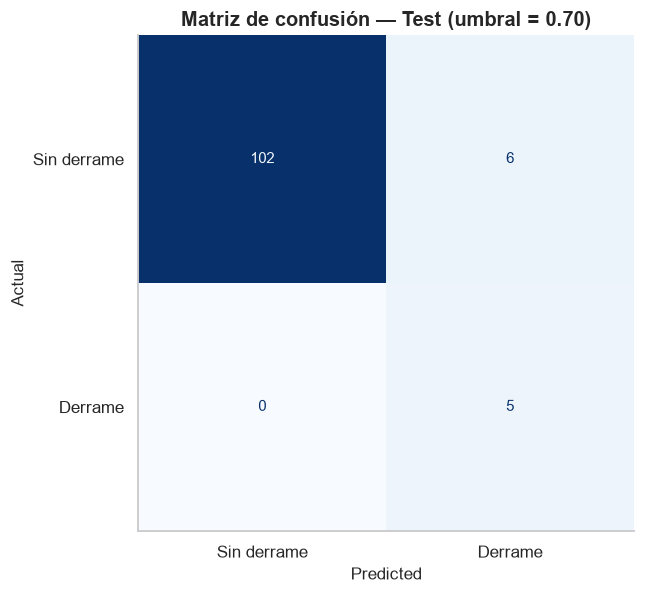

In [209]:
fig, ax = plt.subplots(figsize=(6, 5.5))
ConfusionMatrixDisplay(
    confusion_matrix=test_matrix,
    display_labels=["Sin derrame", "Derrame"],
).plot(
    ax=ax,
    cmap=sns.color_palette("Blues", as_cmap=True),
    colorbar=False,
)

ax.set_title(
    f"Matriz de confusión — Test (umbral = {best_threshold:.2f})"
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.grid(False)
plt.tight_layout()
plt.show()

In [210]:
print(
    classification_report_imbalanced(
        np.ravel(y_test),
        y_test_hat,
        target_names=["class 0:non-spill", "class 1:oil-spill"],
    )
)

                         pre       rec       spe        f1       geo       iba       sup

class 0:non-spill       1.00      0.94      1.00      0.97      0.97      0.94       108
class 1:oil-spill       0.45      1.00      0.94      0.62      0.97      0.95         5

      avg / total       0.98      0.95      1.00      0.96      0.97      0.94       113



In [211]:
pd.DataFrame(
    [
        {
            "split": "Test",
            "family": best_family,
            "C": best_c,
            "umbral": best_threshold,
            "accuracy": test_accuracy,
            "G-mean": test_gmean,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "costo_total_usd": test_cost,
        }
    ]
).style.format(
    {
        "C": "{:.4g}",
        "umbral": "{:.2f}",
        "accuracy": "{:.4f}",
        "G-mean": "{:.4f}",
        "costo_total_usd": "${:,.0f}",
    }
).hide(axis="index")

split,family,C,umbral,accuracy,G-mean,TN,FP,FN,TP,costo_total_usd
Test,EN,7.499,0.70,0.9469,0.9718,102,6,0,5,"$90,000"


## Respuestas de la Actividad (Ejercicios 1–9)

Las respuestas siguientes se basan en los resultados obtenidos en las secciones de código de este notebook.


### Ejercicio-1

**1a)** En este problema la clase positiva (derrame) representa apenas alrededor del **4–5%** de las observaciones. Un modelo que predijera siempre “no hay derrame” alcanzaría una exactitud cercana al **96%** sin detectar ningún derrame. La exactitud, por tanto, premia al clasificador que ignora la clase minoritaria. La media geométrica $G\_mean = \sqrt{\text{sensibilidad} \times \text{especificidad}}$ exige buen desempeño en **ambas** clases; si el modelo falla en la clase positiva, $G\_mean$ cae hacia cero. Como además se asume que falsos positivos y falsos negativos son igualmente costosos en esta primera etapa, $G\_mean$ es una métrica adecuada para comparar modelos bajo desbalanceo.

**1b)** Un **falso positivo** ocurre cuando el modelo predice derrame y en realidad la imagen no lo tiene (por ejemplo, manchas de algas u otros *look-alikes*). Implicaciones: envío innecesario de helicópteros o equipos de inspección, gasto operativo, saturación de analistas y posible “fatiga de alarmas” que reduce la atención a alertas reales.

**1c)** Un **falso negativo** ocurre cuando hay derrame y el modelo predice océano limpio. Implicaciones: el derrame no se detecta a tiempo, crece el daño ecológico, aumentan costos de limpieza de emergencia, multas, impacto reputacional y riesgo para la costa y la vida marina. En la práctica este error suele ser el más grave.


### Ejercicio-2

**2a)** La transformación **Yeo–Johnson** es una transformación de potencia paramétrica que busca acercar la distribución de una variable a una forma más simétrica (aproximadamente normal). Para cada variable se estima un parámetro $\lambda$ que define cómo se “aplanan” colas pesadas o sesgos. A diferencia de un escalado lineal, actúa sobre la forma de la distribución y admite valores **positivos, negativos y cero**.

**2b)** La diferencia principal con **Box–Cox** es el dominio: Box–Cox requiere valores **estrictamente positivos**, mientras que Yeo–Johnson está definida también para ceros y negativos. En este dataset hay variables con valores ≤ 0, por lo que Yeo–Johnson es la opción viable sin tener que desplazar artificialmente las columnas.


### Ejercicio-3

**3a)** Se exploraron las estrategias `most_frequent`, `prior`, `stratified` y `uniform`, con `n_splits` ∈ {2, 3, 5, 7, 10}.

- `most_frequent` / `prior` predicen siempre la clase mayoritaria → sensibilidad = 0 → **$G\_mean = 0$**. No sirven como umbral de subentrenamiento con $G\_mean$.
- `stratified` obtiene $G\_mean$ muy bajo y ruidoso (≈ 0.05–0.11).
- **`uniform`** asigna clases al azar con probabilidad 50/50 y produce un $G\_mean$ cercano a ~0.5, coherente con un clasificador ingenuo “al azar”.

Se eligió **`strategy = "uniform"`** y **`n_splits = 5`**: con 28 positivos en entrenamiento quedan ≈ 5.6 positivos por fold (suficientes para estimar sensibilidad) y la desviación estándar se mantiene aceptable frente a 10 folds (donde hay ~2.8 positivos/fold y mayor varianza). Aunque `n_splits = 3` dio una media ligeramente mayor, 5 folds es un compromiso más estable y estándar para validación cruzada estratificada.

**3b)** Con esa configuración, el umbral de subentrenamiento en $G\_mean$ es el promedio del DummyClassifier:

**Baseline $G\_mean$ ≈ 0.508**.

Todo modelo con $G\_mean$ CV ≤ 0.508 se considera subentrenado respecto a esta referencia.

**3c)** Para exactitud, el baseline ingenuo adecuado es **`most_frequent`** (siempre predice “no derrame”). Su umbral a superar es:

**Baseline accuracy ≈ 0.9575 (≈ 95.75%)**.

La matriz de confusión de ese modelo ingenuo (sobre predicciones de validación cruzada en entrenamiento) concentra todos los casos en la clase negativa: no hay verdaderos positivos ni falsos positivos; los derrames reales quedan como falsos negativos. Eso confirma que una exactitud “alta” puede ocultar un modelo inútil para detectar derrames.


### Ejercicio-4

Resultados de los modelos con hiperparámetros por defecto (CV estratificada repetida), comparados con los baselines:

| Modelo | Accuracy media | ¿Subentrenado (acc)? | $G\_mean$ media | ¿Subentrenado ($G\_mean$)? |
|--------|----------------|----------------------|------------------|------------------------------|
| LR     | 0.9466         | Sí (< 0.9575)        | 0.6517           | No (> 0.508)                 |
| LASSO  | 0.9599         | No                   | 0.5011           | Sí (≤ 0.508)                 |
| RIDGE  | 0.9587         | No                   | 0.5413           | No                           |
| EN     | 0.9595         | No                   | 0.5403           | No                           |
| kNN    | 0.9559         | Sí (< 0.9575)        | 0.1744           | Sí (< 0.508)                 |

**4a)** Respecto a **exactitud**, están subentrenados: **LR** y **kNN**.

**4b)** Respecto a **$G\_mean$**, están subentrenados: **LASSO** y **kNN**.

Interpretación: varios modelos “se ven bien” en exactitud por el desbalanceo, pero en $G\_mean$ el kNN (y en menor medida LASSO por defecto) no superan al clasificador ingenuo uniforme. La LR por defecto ya supera el baseline de $G\_mean$, aunque su exactitud quede por debajo del naive `most_frequent`.


### Ejercicio-5

Se implementó la búsqueda de hiperparámetros (`GridSearchCV` + `RepeatedStratifiedKFold`) maximizando $G\_mean$, incluyendo `class_weight='balanced'` en las regresiones logísticas. Resultados CV (media ± std de $G\_mean$):

| Modelo | $G\_mean$ por defecto | $G\_mean$ ajustado | Mejora |
|--------|------------------------|---------------------|--------|
| LR     | 0.652                  | **0.759 ± 0.123**   | +0.11  |
| LASSO  | 0.501                  | **0.837 ± 0.052**   | +0.34  |
| RIDGE  | 0.541                  | **0.817 ± 0.106**   | +0.28  |
| EN     | 0.540                  | **0.843 ± 0.058**   | +0.30  |
| kNN    | 0.174                  | **0.497 ± 0.101**   | +0.32  |

Mejores hiperparámetros destacados:
- **EN**: `C ≈ 0.032`, `l1_ratio = 0.75`, `class_weight='balanced'`
- **LASSO**: `C = 0.1`, `class_weight='balanced'`
- **RIDGE**: `C = 0.01`, `class_weight='balanced'`
- **LR**: `class_weight='balanced'`
- **kNN**: `n_neighbors = 1`, `p = 1`, `weights='uniform'` (aún cerca del baseline)

Los boxplots de la sección 11 muestran que, tras el ajuste, las familias logísticas con pesos balanceados quedan claramente por encima del baseline $G\_mean$ ≈ 0.508, mientras que kNN sigue siendo el más débil.


### Ejercicio-6

**6a)** El mejor modelo seleccionado fue la familia **Elastic Net (EN)** con `class_weight='balanced'`, `random_state=1`, y $C$ elegido en la curva de validación bajo la restricción de que la diferencia $|G\_mean_{train} - G\_mean_{val}| \leq 3\%$. En validación, con el umbral por defecto 0.5:

- Accuracy ≈ **0.9212**
- $G\_mean$ ≈ **0.9577**
- Matriz de confusión (validación):

```
[[144  13]
 [  0   8]]
```

(TN=144, FP=13, FN=0, TP=8) → **recall de derrames = 100%** en este conjunto de validación.

La brecha train–val se mantuvo dentro del 3%, por lo que no se considera sobreentrenado según el criterio de la actividad.

**6b)** La exactitud del mejor modelo (**≈ 0.92**) es **menor** que la de varios modelos por defecto o del naive `most_frequent` (**≈ 0.96**). Eso es esperado y deseable aquí: al usar `class_weight='balanced'` el modelo deja de “esconderse” en la clase mayoritaria, acepta más falsos positivos (13 en validación) y a cambio detecta los derrames (recall ≈ 1). La exactitud penaliza esos FP; $G\_mean$ refleja el verdadero avance.

**6c / 6d)** En las secciones de curvas ROC y Precisión–Recall sobre validación se incluye el AUC del mejor modelo y el nivel de azar (*chance level*). Para ROC, el azar corresponde a la diagonal (AUC = 0.5). Para PR, el nivel de azar coincide con la **prevalencia** de la clase positiva en validación (**≈ 0.0485**).

**6e)** En un problema tan desbalanceado, la curva ROC puede verse optimista porque los verdaderos negativos abundan y el FPR crece despacio. La curva PR es más informativa: mide qué tan precisas son las alertas de derrame a distintos niveles de recall. Un buen AUC-ROC no basta si la precisión sobre la clase positiva es baja; por eso conviene reportar ambas, priorizando PR y $G\_mean$ / recall de derrames para la decisión operativa.


### Ejercicio-7

**7a / 7b)** Se definió el costo total esperado en validación como:

$$\text{Costo} = 1{,}000{,}000 \cdot FN + 15{,}000 \cdot FP$$

y se evaluó para umbrales de probabilidad de 0.10 a 0.90. El mínimo se alcanza en el intervalo **0.69–0.71**; se seleccionó el centro **umbral óptimo = 0.70**, con costo **$135,000 USD** frente a **$195,000 USD** del umbral 0.50 (ahorro de **$60,000 USD** en validación). La gráfica de la sección 14 marca visualmente ese óptimo.

**7c)** Comparación en validación:

| Umbral | Matriz de confusión | $G\_mean$ | Costo |
|--------|---------------------|------------|-------|
| 0.50   | [[144, 13], [0, 8]] | 0.9577     | $195,000 |
| **0.70** | [[148, 9], [0, 8]] | **0.9709** | **$135,000** |

En ambos casos FN = 0 (no se pierde ningún derrame del conjunto de validación); el umbral 0.70 reduce FP de 13 a 9.

**7d)** Sí vale la pena cambiarlo. El umbral 0.5 es una convención, no un óptimo de negocio. Al subir a **0.70** se exige mayor confianza para disparar una alerta, se cortan falsas alarmas costosas y se mantiene la detección de derrames en validación. La estrategia de despliegue pasa de “alertar con facilidad” a “alertar solo con evidencia más fuerte”, alineada con el costo relativo FN ≫ FP (aunque el FN sigue siendo mucho más caro que un FP, aquí el modelo ya tenía FN=0 y el margen estaba en reducir FP).

**7e) LLM y prompt utilizado**

- **LLM**: Composer (agente de Cursor), asistente de código usado para diseñar/revisar la función de costo y la visualización.
- **Prompt representativo** (adaptado al enunciado 7a–7b):

> “Con mi mejor modelo de detección de derrames ya entrenado, escribe una función en Python que calcule el costo total esperado en el conjunto de validación iterando umbrales de probabilidad de 0.1 a 0.9. Usa costo_FN = 1_000_000 y costo_FP = 15_000 (TP y TN cuestan 0). Devuelve una tabla con umbral, FP, FN y costo, grafica costo vs umbral y marca el umbral óptimo con su costo mínimo.”


### Ejercicio-8 — Reporte ejecutivo al Director de Operaciones

**Asunto:** Por qué un 96% de exactitud no justifica automatizar por completo las inspecciones

Director:

Un reporte de BI afirma que el modelo es “casi perfecto” porque acierta el 96% de las veces y propone despedir analistas y enviar helicópteros en automático. Esa conclusión es peligrosa.

Hoy, la gran mayoría de las imágenes satelitales **no** contienen derrame (alrededor de 19 de cada 20). Un sistema que **nunca** marque derrame tendría casi esa misma exactitud… y fallaría en lo único que importa: encontrar petróleo en el agua. La exactitud premia acertar en el océano limpio; no mide si estamos protegiendo la costa.

Hay dos errores distintos. Una **falsa alarma** (decir que hay derrame cuando no lo hay) cuesta del orden de miles de dólares: horas de vuelo, combustible e inspección. Un **derrame no detectado** puede costar cerca de un millón por evento: daño ambiental, limpieza de emergencia, multas y reputación. No son errores simétricos.

El modelo ingenuo que siempre dice “todo limpio” parece excelente en exactitud, pero **deja pasar todos los derrames**. Nuestro modelo ajustado prioriza no perder derrames: en validación detectó los casos positivos disponibles y, al fijar un umbral de decisión pensado en costos (no el 0.5 por defecto), redujo falsas alarmas y el costo esperado operativo. Aun así, la precisión sobre alertas positivas no es perfecta: varias señales seguirán siendo *look-alikes* (algas, etc.). Por eso un “disparo automático de helicóptero” ante cada alerta generaría gasto y desgaste innecesario.

**Plan de despliegue propuesto (human-in-the-loop), manteniendo 2 analistas:**

1. El modelo puntúa cada escena y genera una **lista priorizada de alertas** (no una orden de vuelo).
2. Los **dos analistas** revisan las alertas de mayor riesgo, confirman o descartan con contexto operativo y meteorológico, y solo entonces autorizan inspección.
3. Los analistas también auditan una muestra de casos “limpios” de alta incertidumbre para detectar fallos silenciosos.
4. Cada decisión humana (confirmar / descartar) se registra para **reentrenar y calibrar** el umbral con costos reales.
5. El tercer puesto no se elimina a ciegas: se redefine como respaldo en picos de alertas, control de calidad y enlace con Guardia Costera / EPA.

En resumen: el 96% de exactitud no prueba que el modelo esté listo para operar solo. Lo que aporta valor es detectar derrames a tiempo, controlar falsas alarmas y dejar la decisión final de despliegue de recursos en manos expertas. La IA debe **aumentar** a los analistas, no sustituirlos en un proceso de alto costo de error.

Atentamente,  
Ingeniería de IA — Guardia Costera


### Ejercicio-9 — Conclusiones finales

1. El dataset oil-spill está **fuertemente desbalanceado** (~4–5% de positivos). La exactitud es engañosa; métricas como $G\_mean$, recall de la clase positiva y curvas PR son más adecuadas.
2. El preprocesamiento con **Yeo–Johnson + estandarización** dentro de un `Pipeline`/`ColumnTransformer` corrige sesgos y evita *data leakage* al usarse dentro de la validación cruzada.
3. El **DummyClassifier `uniform`** fija un baseline de $G\_mean$ ≈ 0.51; `most_frequent` fija un baseline de exactitud ≈ 0.96 que un modelo “perezoso” ya alcanza.
4. Sin ajuste, varios modelos se ven bien en exactitud pero aportan poco en $G\_mean$. Con **`class_weight='balanced'`** e hiperparámetros, las regresiones regularizadas (sobre todo **Elastic Net**) mejoran de forma clara.
5. El mejor modelo mantiene alta detección de derrames en validación; la exactitud baja respecto al naive porque acepta más FP a cambio de no perder TP.
6. ROC y PR deben leerse juntas: con desbalanceo, **PR** refleja mejor el valor práctico de las alertas.
7. Incorporar **costos de negocio** mueve el umbral de 0.5 a **≈ 0.70**, reduce falsas alarmas y el costo esperado sin sacrificar detección en validación/test en este ejercicio.
8. El despliegue responsable es **human-in-the-loop**: el modelo prioriza; los analistas deciden. Un 96% de exactitud no autoriza sustituir por completo la supervisión humana.


# Fin de las respuestas de la actividad
